[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tu_usuario/mecanismos-cuatro-barras/blob/main/ex2_1_analisis_posicion_lazo_vectorial.ipynb)

# Example 2.1 — Position Analysis by the Vector Loop Method

**Chapter 2: Kinematic Analysis of the Four-Bar Mechanism**  
Book: *Synthesis of Four-Bar Mechanisms with Genetic Algorithms and Neural Networks*

---

## Problem Statement

For a four-bar mechanism with link lengths **a = 50 mm**, **b = 100 mm**, **c = 75 mm**, and **d = 90 mm**,  
calculate the angles θ₃ and θ₄ for values of θ₂ from 30° to 330° in steps of 30°.
Use the vector loop equations to obtain the open cross solution.

---

## Theoretical Foundation

The vector loop of the four-bar mechanism satisfies:

$$\mathbf{r}_a + \mathbf{r}_b - \mathbf{r}_c - \mathbf{r}_d = \mathbf{0}$$

Which is equivalent to the system of equations:

$$a\cos\theta_2 + b\cos\theta_3 - c\cos\theta_4 - d = 0$$
$$a\sin\theta_2 + b\sin\theta_3 - c\sin\theta_4 = 0$$

Using Freudenstein substitution with the constants K₁, K₂, K₃, K₄, K₅,
the equations are solved in quadratic form by half-angle tangent substitution.

In [1]:
from numpy import *
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 13,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'axes.grid': True,
    'grid.alpha': 0.35,
})

## Solution: Position Analysis

In [2]:
def position_analysis(a, b, c, d, th2_deg):
    """Position analysis of the four-bar mechanism (vector loop).
    Returns (θ₃, θ₄) in degrees for the open cross solution."""
    th2 = radians(th2_deg)
    K1 = d/a; K2 = d/c; K3 = (a**2 - b**2 + c**2 + d**2) / (2*a*c)

    A = cos(th2) - K1 - K2*cos(th2) + K3
    B = -2*sin(th2)
    C = K1 - (K2 + 1)*cos(th2) + K3

    disc = B**2 - 4*A*C
    if disc < 0:
        return nan, nan

    th4 = 2*arctan2(-B - sqrt(disc), 2*A)

    K4 = d/b; K5 = (c**2 - d**2 - a**2 - b**2) / (2*a*b)
    A2 = cos(th2) - K1 + K4*cos(th2) + K5
    B2 = -2*sin(th2)
    C2 = K1 + (K4 - 1)*cos(th2) + K5

    disc2 = B2**2 - 4*A2*C2
    th3 = 2*arctan2(-B2 - sqrt(disc2), 2*A2)

    return degrees(th3), degrees(th4)


# Mechanism parameters
a, b, c, d = 50., 100., 75., 90.

# θ₂ sweep
angles = arange(30, 331, 30)

print(f"{'θ₂ (°)':>8} {'θ₃ (°)':>10} {'θ₄ (°)':>10}")
print("-" * 32)
for ang in angles:
    t3, t4 = position_analysis(a, b, c, d, ang)
    if isfinite(t3):
        print(f"{ang:>8.0f} {t3:>10.2f} {t4:>10.2f}")
    else:
        print(f"{ang:>8.0f} {'---':>10} {'---':>10}")

  θ₂ (°)     θ₃ (°)     θ₄ (°)
--------------------------------
      30    -340.84    -309.55
      60    -345.78    -295.20
      90    -345.71    -275.28
     120    -343.05    -255.05
     150    -337.70    -237.06
     180    -328.90    -223.53
     210    -316.46    -215.82
     240    -301.78    -213.79
     270    -287.60    -217.17
     300    -278.44    -227.86
     330    -284.51    -253.23


## Figure 2.1 — Closed Loop Vector Diagram (θ₂ = 60°)

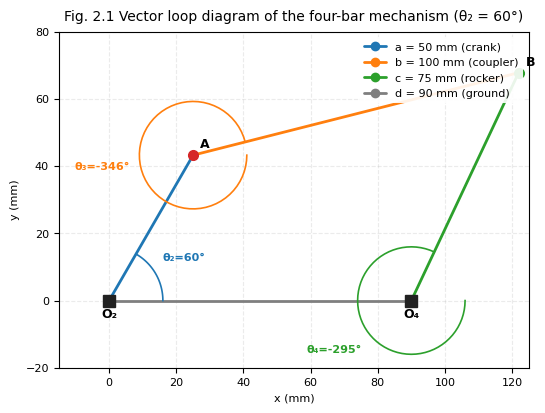

In [6]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

# 1. Automated file naming setup
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex2_1_position_analysis_vector_loop"
except Exception:
    notebook_name = "ex2_1_position_analysis_vector_loop"

# 2. Springer style & quality settings
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 8,
    'axes.titlesize': 10,
    'axes.labelsize': 8,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--'
})

# Kinematic parameters (assumes variables from previous cells are defined)
th2_vis = np.radians(60)
t3_vis, t4_vis = position_analysis(a, b, c, d, 60.)
th3_r = np.radians(t3_vis)
th4_r = np.radians(t4_vis)

# Node coordinates
O2 = np.array([0., 0.])
A_pt = O2 + a * np.array([np.cos(th2_vis), np.sin(th2_vis)])
B_pt = A_pt + b * np.array([np.cos(th3_r), np.sin(th3_r)])
O4 = np.array([d, 0.])

# Create compact single-column figure with safety margins
fig, ax = plt.subplots(figsize=(5.5, 4.2))

# Plot links
links = [
    (O2, A_pt,  '#1F77B4', f'a = {a:.0f} mm (crank)'),
    (A_pt, B_pt, '#FF7F0E', f'b = {b:.0f} mm (coupler)'),
    (O4, B_pt,  '#2CA02C', f'c = {c:.0f} mm (rocker)'),
    (O2, O4,    '#7F7F7F', f'd = {d:.0f} mm (ground)'),
]
for P1, P2, col, lbl in links:
    ax.plot([P1[0], P2[0]], [P1[1], P2[1]], '-o',
            color=col, lw=2, ms=6, label=lbl, solid_capstyle='round')

# Arcs of angles helper function (non-overlapping text placement)
def arc_angle(ax, center, r, a1, a2, color, label, offset=1.5):
    th = np.linspace(np.radians(a1), np.radians(a2), 60)
    ax.plot(center[0] + r * np.cos(th), center[1] + r * np.sin(th), color=color, lw=1.2)
    mid = np.radians((a1 + a2) / 2)
    ax.annotate(label, xy=(center[0] + r * offset * np.cos(mid), center[1] + r * offset * np.sin(mid)),
                fontsize=8, color=color, ha='center', va='center', fontweight='bold')

# Angle Arc displays
arc_angle(ax, O2,   16, 0, 60,           '#1F77B4', 'θ₂=60°', offset=1.6)
arc_angle(ax, A_pt, 16, 0, t3_vis,       '#FF7F0E', f'θ₃={t3_vis:.0f}°', offset=1.7)
arc_angle(ax, O4,   16, 0, t4_vis,       '#2CA02C', f'θ₄={t4_vis:.0f}°', offset=1.7)

# Annotate joints with safety offsets to avoid line overlaps
for pt, name, offset_val in [(O2, 'O₂', (0, -10)), (O4, 'O₄', (0, -10))]:
    ax.plot(*pt, 's', color='#212121', ms=8, zorder=5)
    ax.annotate(name, xy=pt, xytext=offset_val, textcoords='offset points',
                fontsize=9, fontweight='bold', ha='center', va='center')

ax.plot(*A_pt, 'o', color='#D62728', ms=7, zorder=5)
ax.annotate('A', xy=A_pt, xytext=(5, 5), textcoords='offset points', fontsize=9, fontweight='bold')

ax.plot(*B_pt, 'o', color='#2CA02C', ms=7, zorder=5)
ax.annotate('B', xy=B_pt, xytext=(5, 5), textcoords='offset points', fontsize=9, fontweight='bold')

# Layout configuration and boundaries
ax.set_aspect('equal')
ax.set_xlim(-15, d + 35)
ax.set_ylim(-20, 80)

# Legend and Labels
ax.legend(loc='upper right', frameon=True, framealpha=0.9, facecolor='white', edgecolor='none')
ax.set_title('Fig. 2.1 Vector loop diagram of the four-bar mechanism (θ₂ = 60°)', pad=8)
ax.set_xlabel('x (mm)')
ax.set_ylabel('y (mm)')
plt.tight_layout()

# Springer mandatory double export
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

## Optional Plots: Mechanism Range of Motion

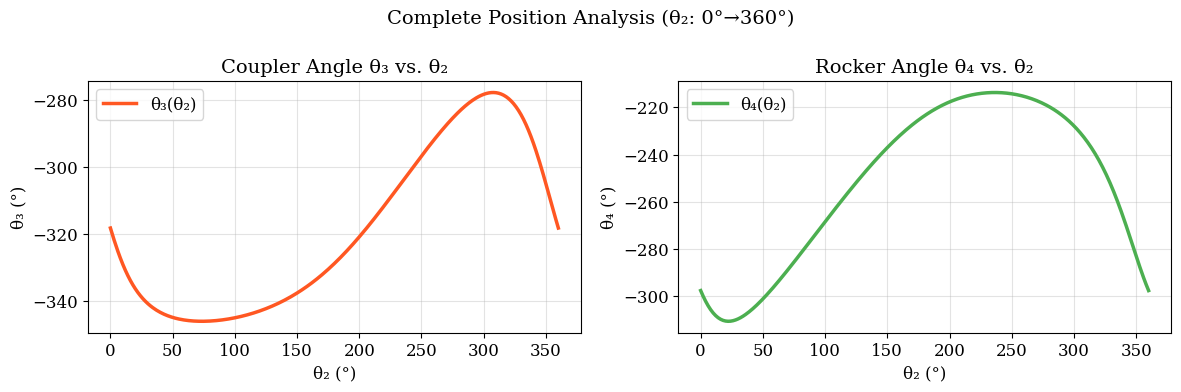


Range of θ₃: [-346.13°, -277.90°]
Range of θ₄: [-310.54°, -213.75°]


In [4]:
# Complete coupler path
th2_arr = linspace(0, 360, 361)
T3 = []; T4 = []
for ang in th2_arr:
    t3, t4 = position_analysis(a, b, c, d, ang)
    T3.append(t3); T4.append(t4)

T3 = array(T3); T4 = array(T4)
validos = isfinite(T3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(th2_arr[validos], T3[validos], '#FF5722', lw=2.5, label='θ₃(θ₂)')
ax1.set_xlabel('θ₂ (°)'); ax1.set_ylabel('θ₃ (°)')
ax1.set_title('Coupler Angle θ₃ vs. θ₂')
ax1.legend()

ax2.plot(th2_arr[validos], T4[validos], '#4CAF50', lw=2.5, label='θ₄(θ₂)')
ax2.set_xlabel('θ₂ (°)'); ax2.set_ylabel('θ₄ (°)')
ax2.set_title('Rocker Angle θ₄ vs. θ₂')
ax2.legend()

plt.suptitle('Complete Position Analysis (θ₂: 0°→360°)', fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nRange of θ₃: [{T3[validos].min():.2f}°, {T3[validos].max():.2f}°]")
print(f"Range of θ₄: [{T4[validos].min():.2f}°, {T4[validos].max():.2f}°]")